# 01. Aquisição, qualidade e EDA do subconjunto Disque 100

**Escopo:** denúncias de tráfico de pessoas e violações coocorrentes.

**Unidade física do arquivo:** linha do CSV. A unidade substantiva será validada por `hash`, pois uma denúncia pode ocupar várias linhas, especialmente quando há mais de uma `violacao`.

**Saídas:** dados limpos em nível de linha, base agregada por denúncia, matriz binária de violações, relatório de correções e comparação antes/depois.


## 1. Configuração do ambiente


In [2]:
from pathlib import Path
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

DATA_FILE = Path(r"C:\Projetos\eda-disque100-completo\data\trafico-pessoas-com-outras-violacoes-2021-2025.csv")
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LIMIAR_AUSENCIA_COLUNA = 0.80
RANDOM_STATE = 42


## 2. Carregamento e validação do esquema


In [3]:
COLUNAS_ESPERADAS = ['hash', 'data_de_cadastro', 'canal_de_atendimento', 'denuncia_emergencial', 'denunciante', 'cenario_da_violacao', 'pais', 'uf', 'municipio', 'frequencia', 'inicio_das_violacoes', 'sl_quantidade_vitimas', 'grupo_vulneravel', 'motivacao', 'relacao_vitima_suspeito', 'sl_vitima_cadastro', 'genero_da_vitima', 'orientacao_sexual_da_vitima', 'faixa_etaria_da_vitima', 'nacionalidade_da_vitima', 'sl_vitima_naturalidade', 'sl_vitima_naturalizado_uf', 'sl_vitima_naturalizado_municipio', 'deficiencia_da_vitima', 'doenca_rara_da_vitima', 'deficiencia_relacionada_a_doenca_rara', 'vitima_preso_a', 'pais_da_vitima', 'uf_da_vitima', 'municipio_da_vitima', 'profissao_da_vitima', 'grau_de_instrucao_da_vitima', 'religiao_da_vitima', 'raca_cor_da_vitima', 'etnia_da_vitima', 'faixa_de_renda_da_vitima', 'natureza_juridica_do_suspeito', 'genero_do_suspeito', 'orientacao_sexual_do_suspeito', 'faixa_etaria_do_suspeito', 'suspeito_nacionalidade', 'sl_suspeito_naturalidade', 'sl_suspeito_naturalizado_uf', 'sl_suspeito_naturalizado_municipio', 'deficiencia_do_suspeito', 'doenca_rara_do_suspeito', 'deficiencia_relacionada_a_doenca_rara_suspeito', 'suspeito_preso', 'pais_do_suspeito', 'uf_do_suspeito', 'sl_suspeito_municipio', 'profissao_do_suspeito', 'grau_de_instrucao_do_suspeito', 'religiao_do_suspeito', 'raca_cor_do_suspeito', 'suspeito_etnia', 'faixa_de_renda_do_suspeito', 'vinculo_orgao_pj_do_suspeito', 'sl_suspeito_ramo', 'suspeito_especificacao_etnia', 'vitima_especificacao_etnia', 'violacao']

df_raw = pd.read_csv(DATA_FILE, sep=";", encoding="utf-8", low_memory=False)
faltantes = sorted(set(COLUNAS_ESPERADAS) - set(df_raw.columns))
extras = sorted(set(df_raw.columns) - set(COLUNAS_ESPERADAS))
assert not faltantes, f"Colunas esperadas ausentes: {faltantes}"
print("Colunas extras:", extras)
print("Dimensão bruta:", df_raw.shape)
df_raw.head()


Colunas extras: []
Dimensão bruta: (8401, 62)


,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,1b13f107009820e1bc2f357e81b77d58,2021-01-05 08:28:00,CARTA,N/D,TERCEIRO,VIA PÚBLICA,BRASIL,RJ,RIO DE JANEIRO,DIARIAMENTE,HÁ MAIS DE UM ANO,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DO AGRESSOR POSSUIR INFLUÊNCIA JUNTO ÀS AUTORI...,NÃO SE APLICA,PESSOA FÍSICA,FEMININO,N/D,NaN,N/D,NaN,NaN,NaN,NÃO TEM DEFICIÊNCIA,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,RJ,RIO DE JANEIRO,N/D,N/D,N/D,N/D,N/D,N/D,COMUNIDADE,N/D,N/D,N/D,N/D,NaN,NaN,NaN,N/D,N/D,NÃO SABE INFORMAR,N/D,BRASIL,RJ,RIO DE JANEIRO,N/D,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
1,cf00afd3f64f95998f3b74a05078e709,2021-01-08 07:02:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,SEMANALMENTE,HÁ MAIS DE SEIS MESES,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,PARA OBTENÇÃO DE BENEFÍCIO FINANCEIRO/ GANÂNCIA,MÃE,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,PESSOA FÍSICA,FEMININO,N/D,30 A 34 ANOS,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
2,cf00afd3f64f95998f3b74a05078e709,2021-01-08 07:02:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,SEMANALMENTE,HÁ MAIS DE SEIS MESES,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DA COABITAÇÃO/ CONVIVÊNCIA FAMILIAR/ RELAÇÃO A...,MÃE,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,PESSOA FÍSICA,FEMININO,N/D,30 A 34 ANOS,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,NaN
3,cf00afd3f64f95998f3b74a05078e709,2021-01-08 07:02:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,SEMANALMENTE,HÁ MAIS DE SEIS MESES,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DO AGRESSOR POSSUIR INFLUÊNCIA JUNTO ÀS AUTORI...,MÃE,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,NÃO TEM DEFICIÊNCIA,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,PESSOA FÍSICA,FEMININO,N/D,30 A 34 ANOS,N/D,NaN,NaN,NaN,NÃO TEM DEFICIÊNCIA,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>INSUBSISTÊNCIA AFETIVA
4,8b7144580f23532784a267f38de0a7d9,2021-01-08 22:04:00,TELEFÔNICO,NÃO,ANÔNIMO,OUTROS,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,EM RAZÃO DA IDADE,OUTROS,PESSOA FÍSICA,FEMININO,N/D,12 A 

In [4]:
df_raw.dtypes

hash                                                  str
data_de_cadastro                                      str
canal_de_atendimento                                  str
denuncia_emergencial                                  str
denunciante                                           str
cenario_da_violacao                                   str
pais                                                  str
uf                                                    str
municipio                                             str
frequencia                                            str
inicio_das_violacoes                                  str
sl_quantidade_vitimas                               int64
grupo_vulneravel                                      str
motivacao                                             str
relacao_vitima_suspeito                               str
sl_vitima_cadastro                                    str
genero_da_vitima                                      str
orientacao_sex

In [5]:
df_raw.isnull().mean().sort_values(ascending=False)

vinculo_orgao_pj_do_suspeito                      1.000000
deficiencia_relacionada_a_doenca_rara             0.977741
sl_vitima_naturalizado_municipio                  0.974765
sl_vitima_naturalizado_uf                         0.969051
sl_suspeito_naturalizado_municipio                0.967861
sl_vitima_naturalidade                            0.962147
sl_suspeito_naturalizado_uf                       0.957743
sl_suspeito_naturalidade                          0.954053
faixa_de_renda_do_suspeito                        0.887275
grau_de_instrucao_do_suspeito                     0.887275
deficiencia_relacionada_a_doenca_rara_suspeito    0.887275
faixa_de_renda_da_vitima                          0.885371
suspeito_especificacao_etnia                      0.884061
etnia_da_vitima                                   0.883466
suspeito_etnia                                    0.882752
vitima_especificacao_etnia                        0.882038
religiao_do_suspeito                              0.8607

### 2.1 Conversão dos tipos conhecidos


In [6]:
df = df_raw.copy(deep=True)
df["data_de_cadastro"] = pd.to_datetime(df["data_de_cadastro"], format="mixed").astype("datetime64[ns]")
# df["data_de_cadastro"] = df["data_de_cadastro"].dt.floor("s") 
df["sl_quantidade_vitimas"] = pd.to_numeric(df["sl_quantidade_vitimas"], errors="coerce").astype("Int64")
df["vinculo_orgao_pj_do_suspeito"] = df["vinculo_orgao_pj_do_suspeito"].astype("str")

erros_data = int(df["data_de_cadastro"].isna().sum() - df_raw["data_de_cadastro"].isna().sum())
erros_quantidade = int(df["sl_quantidade_vitimas"].isna().sum() - df_raw["sl_quantidade_vitimas"].isna().sum())
print({"datas_nao_convertidas": erros_data, "quantidades_nao_convertidas": erros_quantidade})
df.info()


{'datas_nao_convertidas': 0, 'quantidades_nao_convertidas': 0}
<class 'pandas.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype         
---  ------                                          --------------  -----         
 0   hash                                            8401 non-null   str           
 1   data_de_cadastro                                8401 non-null   datetime64[ns]
 2   canal_de_atendimento                            8401 non-null   str           
 3   denuncia_emergencial                            8401 non-null   str           
 4   denunciante                                     8401 non-null   str           
 5   cenario_da_violacao                             8401 non-null   str           
 6   pais                                            8401 non-null   str           
 7   uf                                              7828 non-null   str           
 

## 3. Compreensão da granularidade


In [7]:
granularidade = pd.Series({
    "linhas": len(df),
    "hash_unicos": df["hash"].nunique(dropna=True),
    "hash_repetidos_linhas": int(df["hash"].duplicated(keep=False).sum()),
    "linhas_duplicadas_exatas": int(df.duplicated().sum()),
    "violacoes_unicas": df["violacao"].nunique(dropna=True)
})
display(granularidade.to_frame("valor"))

linhas_por_denuncia = df.groupby("hash", dropna=False).size()
display(linhas_por_denuncia.describe().to_frame("linhas_por_hash"))


,valor
linhas,8401
hash_unicos,1263
hash_repetidos_linhas,8304
linhas_duplicadas_exatas,0
violacoes_unicas,101


,linhas_por_hash
count,1263.000000
mean,6.651623
std,6.762833
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,140.000000


### Decisão metodológica

- Preserve a base em nível de linha para auditoria e EDA.
- Para clusterização e detecção de anomalias, agregue por `hash` para evitar que denúncias com várias violações recebam peso maior.
- Para associação, use uma matriz denúncia × violação, também indexada por `hash`.


## 4. Avaliação da qualidade dos dados


### 4.1 Completude explícita


In [8]:
relatorio_missing_explicito = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nao-nulos": df.notna().sum(),
    "percentual": df.isna().mean().mul(100).round(2),
    "unicos": df.nunique(dropna=True)
}).sort_values("percentual", ascending=False)
display(relatorio_missing_explicito)


,tipo,nulos,nao-nulos,percentual,unicos
vinculo_orgao_pj_do_suspeito,str,8401,0,100.00,0
deficiencia_relacionada_a_doenca_rara,str,8214,187,97.77,2
sl_vitima_naturalizado_municipio,str,8189,212,97.48,25
sl_vitima_naturalizado_uf,str,8141,260,96.91,16
sl_suspeito_naturalizado_municipio,str,8131,270,96.79,31
sl_vitima_naturalidade,str,8083,318,96.21,1
sl_suspeito_naturalizado_uf,str,8046,355,95.77,14
sl_suspeito_naturalidade,str,8015,386,95.41,2
faixa_de_renda_do_suspeito,str,7454,947,88.73,5
grau_de_instrucao_do_suspeito,str,7454,947,88.73,7


In [9]:
# Count the number of missing values in each column
print(df.isna().sum())

# Find the five percent threshold
threshold = len(df) * 0.05

# Create a filter
cols_to_drop = df.columns[df.isna().sum() <= threshold]

cols_to_drop


# Drop missing values for columns below the threshold
# planes.dropna(subset=cols_to_drop, inplace=True)
df.dropna(subset=cols_to_drop)

print(df.isna().sum())


hash                                                 0
data_de_cadastro                                     0
canal_de_atendimento                                 0
denuncia_emergencial                                 0
denunciante                                          0
cenario_da_violacao                                  0
pais                                                 0
uf                                                 573
municipio                                          591
frequencia                                           0
inicio_das_violacoes                                 0
sl_quantidade_vitimas                                0
grupo_vulneravel                                     0
motivacao                                         5465
relacao_vitima_suspeito                              0
sl_vitima_cadastro                                   0
genero_da_vitima                                  1134
orientacao_sexual_da_vitima                       2371
faixa_etar

### 4.2 Valores ausentes implícitos


In [10]:
MISSING_TEXT = {
    "", "NA", "N/A", "NULL", "NULO", "IGNORADO", "NAO INFORMADO",
    "NAO SABE", "NAO SE APLICA", "SEM INFORMACAO", "SEM PREENCHIMENTO",
    "DESCONHECIDO", "INDEFINIDO", "OUTROS/NAO INFORMADO"
}
MISSING_CODES = {-95, -97, -98, -99, -999}

def normalizar_texto(v):
    if pd.isna(v): return np.nan
    t = re.sub(r"\s+", " ", str(v)).strip().upper()
    return "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))

def mascara_missing_implicito(s):
    if pd.api.types.is_numeric_dtype(s): return s.isin(MISSING_CODES)
    n = s.map(normalizar_texto)
    return n.isin(MISSING_TEXT | {str(x) for x in MISSING_CODES})

implicit_rows=[]
for col in df.columns:
    m=mascara_missing_implicito(df[col])
    implicit_rows.append({"coluna":col,"quantidade":int(m.sum()),"percentual":round(m.mean()*100,2)})
relatorio_missing_implicito=pd.DataFrame(implicit_rows)
relatorio_missing_implicito.query("quantidade > 0").sort_values("quantidade",ascending=False)
# print(f"Total? {len(relatorio_missing_implicito)}")


,coluna,quantidade,percentual
33,raca_cor_da_vitima,3210,38.21
47,suspeito_preso,1476,17.57
10,inicio_das_violacoes,1046,12.45
54,raca_cor_do_suspeito,1012,12.05
39,faixa_etaria_do_suspeito,955,11.37
26,vitima_preso_a,543,6.46
17,orientacao_sexual_da_vitima,391,4.65
16,genero_da_vitima,320,3.81
14,relacao_vitima_suspeito,317,3.77
32,religiao_da_vitima,260,3.09


In [11]:
cols_with_missing_values = df.columns[df.isnull().sum() > 0]
cols_with_missing_values

Index(['uf', 'municipio', 'motivacao', 'genero_da_vitima',
       'orientacao_sexual_da_vitima', 'faixa_etaria_da_vitima',
       'sl_vitima_naturalidade', 'sl_vitima_naturalizado_uf',
       'sl_vitima_naturalizado_municipio', 'deficiencia_da_vitima',
       'doenca_rara_da_vitima', 'deficiencia_relacionada_a_doenca_rara',
       'vitima_preso_a', 'uf_da_vitima', 'municipio_da_vitima',
       'profissao_da_vitima', 'grau_de_instrucao_da_vitima',
       'religiao_da_vitima', 'raca_cor_da_vitima', 'etnia_da_vitima',
       'faixa_de_renda_da_vitima', 'genero_do_suspeito',
       'orientacao_sexual_do_suspeito', 'faixa_etaria_do_suspeito',
       'suspeito_nacionalidade', 'sl_suspeito_naturalidade',
       'sl_suspeito_naturalizado_uf', 'sl_suspeito_naturalizado_municipio',
       'deficiencia_do_suspeito', 'doenca_rara_do_suspeito',
       'deficiencia_relacionada_a_doenca_rara_suspeito', 'suspeito_preso',
       'uf_do_suspeito', 'sl_suspeito_municipio', 'profissao_do_suspeito',
      

In [12]:
df[cols_with_missing_values].info()

<class 'pandas.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 45 columns):
 #   Column                                          Non-Null Count  Dtype
---  ------                                          --------------  -----
 0   uf                                              7828 non-null   str  
 1   municipio                                       7810 non-null   str  
 2   motivacao                                       2936 non-null   str  
 3   genero_da_vitima                                7267 non-null   str  
 4   orientacao_sexual_da_vitima                     6030 non-null   str  
 5   faixa_etaria_da_vitima                          7996 non-null   str  
 6   sl_vitima_naturalidade                          318 non-null    str  
 7   sl_vitima_naturalizado_uf                       260 non-null    str  
 8   sl_vitima_naturalizado_municipio                212 non-null    str  
 9   deficiencia_da_vitima                           1988 non-null   str  
 10 

In [13]:
df["vinculo_orgao_pj_do_suspeito"].replace(np.nan, pd.NA)

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
8396    NaN
8397    NaN
8398    NaN
8399    NaN
8400    NaN
Name: vinculo_orgao_pj_do_suspeito, Length: 8401, dtype: str

In [14]:
del df["vinculo_orgao_pj_do_suspeito"]

In [15]:
for col in df.columns:
    print(f"Col: {col}")
    df[col].fillna(df[col].mode()[0])

Col: hash
Col: data_de_cadastro
Col: canal_de_atendimento
Col: denuncia_emergencial
Col: denunciante
Col: cenario_da_violacao
Col: pais
Col: uf
Col: municipio
Col: frequencia
Col: inicio_das_violacoes
Col: sl_quantidade_vitimas
Col: grupo_vulneravel
Col: motivacao
Col: relacao_vitima_suspeito
Col: sl_vitima_cadastro
Col: genero_da_vitima
Col: orientacao_sexual_da_vitima
Col: faixa_etaria_da_vitima
Col: nacionalidade_da_vitima
Col: sl_vitima_naturalidade
Col: sl_vitima_naturalizado_uf
Col: sl_vitima_naturalizado_municipio
Col: deficiencia_da_vitima
Col: doenca_rara_da_vitima
Col: deficiencia_relacionada_a_doenca_rara
Col: vitima_preso_a
Col: pais_da_vitima
Col: uf_da_vitima
Col: municipio_da_vitima
Col: profissao_da_vitima
Col: grau_de_instrucao_da_vitima
Col: religiao_da_vitima
Col: raca_cor_da_vitima
Col: etnia_da_vitima
Col: faixa_de_renda_da_vitima
Col: natureza_juridica_do_suspeito
Col: genero_do_suspeito
Col: orientacao_sexual_do_suspeito
Col: faixa_etaria_do_suspeito
Col: suspeit

### 4.3 Consistência textual


In [16]:
rows=[]
for col in df.select_dtypes(include=["object","string","category"]).columns:
    original=df[col].dropna().astype(str)
    norm=original.map(normalizar_texto)
    rows.append({"coluna":col,"categorias_originais":original.nunique(),"categorias_normalizadas":norm.nunique(),"reducao_potencial":original.nunique()-norm.nunique()})
relatorio_consistencia=pd.DataFrame(rows).sort_values("reducao_potencial",ascending=False)
relatorio_consistencia


,coluna,categorias_originais,categorias_normalizadas,reducao_potencial
58,violacao,101,100,1
1,canal_de_atendimento,8,8,0
0,hash,1263,1263,0
3,denunciante,6,6,0
4,cenario_da_violacao,28,28,0
5,pais,29,29,0
6,uf,30,30,0
7,municipio,313,313,0
8,frequencia,7,7,0
9,inicio_das_violacoes,9,9,0


### 4.4 Conformidade


In [17]:
UFS = {"AC","AL","AP","AM","BA","CE","DF","ES","GO","MA","MT","MS","MG","PA","PB","PR","PE","PI","RJ","RN","RS","RO","RR","SC","SP","SE","TO"}
COLUNAS_UF = ["uf","uf_da_vitima","sl_vitima_naturalizado_uf","uf_do_suspeito","sl_suspeito_naturalizado_uf"]
conformidade=[]
for col in COLUNAS_UF:
    valores=df[col].map(normalizar_texto)
    invalidos=valores.notna() & ~valores.isin(UFS)
    conformidade.append({"coluna":col,"invalidos":int(invalidos.sum()),"exemplos":sorted(valores[invalidos].unique())[:10]})

q=df["sl_quantidade_vitimas"]
conformidade.append({"coluna":"sl_quantidade_vitimas","invalidos":int((q.notna() & (q<1)).sum()),"exemplos":sorted(q[q.notna() & (q<1)].unique().tolist())})
pd.DataFrame(conformidade)


,coluna,invalidos,exemplos
0,uf,927,"[ATENDIMENTO INTERROMPIDO, DENUNCIANTE NAO SOU..."
1,uf_da_vitima,1416,"[ATENDIMENTO INTERROMPIDO, DENUNCIANTE NAO SOU..."
2,sl_vitima_naturalizado_uf,52,[DENUNCIANTE NAO SOUBE INFORMAR]
3,uf_do_suspeito,1202,"[ATENDIMENTO INTERROMPIDO, DENUNCIANTE NAO SOU..."
4,sl_suspeito_naturalizado_uf,98,[DENUNCIANTE NAO SOUBE INFORMAR]
5,sl_quantidade_vitimas,0,[]


### 4.5 Unicidade


In [18]:
print("Duplicatas exatas:", int(df.duplicated().sum()))
print("Duplicatas por hash + violacao:", int(df.duplicated(subset=["hash","violacao"]).sum()))
df[~df.duplicated(subset=["hash","violacao"], keep=False)].sort_values(["hash","violacao"]).head(20)


Duplicatas exatas: 0
Duplicatas por hash + violacao: 748


,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
4028,002F819E35D44A499A7A94986A57219BF5D730B561452B...,2024-08-09 21:40:20,WHATSAPP,NÃO,A PRÓPRIA VÍTIMA,OUTROS,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,1,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,AGRAVANTE.DO AGRESSOR POSSUIR INFLUÊNCIA JUNTO...,OUTROS,PESSOA FÍSICA,NÃO INFORMADO,NÃO,15 ANOS,BR | BRASIL,NaN,NaN,NaN,NÃO,NÃO,NaN,NÃO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NaN,NaN,NaN,NÃO INFORMADO,NaN,NaN,ÓRGÃO PÚBLICO,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,CE,2301604 | ASSARÉ,NaN,NaN,NaN,NaN,NaN,NaN,MINISTÉRIO PÚBLICO - FEDERAL,NaN,NaN,INTEGRIDADE>FÍSICA>OUTROS
4023,002F819E35D44A499A7A94986A57219BF5D730B561452B...,2024-08-09 21:40:20,WHATSAPP,NÃO,A PRÓPRIA VÍTIMA,OUTROS,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,1,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,OUTRO(S) ELEMENTO(S),OUTROS,PESSOA FÍSICA,NÃO INFORMADO,NÃO,15 ANOS,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NaN,NaN,NaN,NÃO INFORMADO,NaN,NaN,ÓRGÃO PÚBLICO,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,CE,2301604 | ASSARÉ,NaN,NaN,NaN,NaN,NaN,NaN,MINISTÉRIO PÚBLICO - FEDERAL,NaN,NaN,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
4024,002F819E35D44A499A7A94986A57219BF5D730B561452B...,2024-08-09 21:40:20,WHATSAPP,NÃO,A PRÓPRIA VÍTIMA,OUTROS,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,1,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,NaN,OUTROS,PESSOA FÍSICA,NÃO INFORMADO,NÃO,15 ANOS,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NaN,NaN,NaN,NÃO INFORMADO,NaN,NaN,ÓRGÃO PÚBLICO,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,CE,2301604 | ASSARÉ,NaN,NaN,NaN,NaN,NaN,NaN,MINISTÉRIO PÚBLICO - FEDERAL,NaN,NaN,INTEGRIDADE>PSÍQUICA>CONSTRANGIMENTO
4020,002F819E35D44A499A7A94986A57219BF5D730B561452B...,2024-08-09 21:40:20,WHATSAPP,NÃO,A PRÓPRIA VÍTIMA,OUTROS,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,1,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,NaN,OUTROS,PESSOA FÍSICA,NÃO INFORMADO,NÃO,15 ANOS,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NaN,NaN,NaN,NÃO INFORMADO,NaN,NaN,ÓRGÃO PÚBLICO,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,CE,2301604 | ASSARÉ,NaN,NaN,NaN,NaN,NaN,NaN,MINISTÉRIO PÚBLICO - FEDERAL,NaN,NaN,INTEGRIDADE>PSÍQUICA>TORTURA PSÍQUICA
4026,002F819E35D44A499A7A949

### 4.6 Relatório de correções aplicadas


In [19]:
correcoes=[]
def registrar(etapa,objeto,quantidade,regra,justificativa):
    correcoes.append({"etapa":etapa,"objeto":objeto,"quantidade":int(quantidade),"regra":regra,"justificativa":justificativa})

df_antes_limpeza=df.copy(deep=True)

# Ausências implícitas
for col in df.columns:
    m=mascara_missing_implicito(df[col]); n=int(m.sum())
    if n:
        df.loc[m,col]=np.nan
        registrar("Conversão de ausência implícita",col,n,"Marcadores semânticos/códigos -> NaN","Representação uniforme da ausência")

# Texto
for col in df.select_dtypes(include=["object","string","category"]).columns:
    antes=df[col].copy(); depois=df[col].map(normalizar_texto)
    n=int((antes.fillna("<NA>").astype(str)!=depois.fillna("<NA>").astype(str)).sum())
    df[col]=depois
    if n: registrar("Padronização textual",col,n,"Maiúsculas, trim, espaços e acentos","Uniformizar categorias")

# Duplicatas exatas
n=int(df.duplicated().sum())
if n:
    df=df.drop_duplicates().copy()
    registrar("Remoção de duplicatas","linhas",n,"Duplicatas exatas","Unicidade")

# Colunas >80% ausentes após normalização
pct=df.isna().mean()
cols_alta_ausencia=pct[pct>LIMIAR_AUSENCIA_COLUNA].index.tolist()
for col in cols_alta_ausencia:
    registrar("Remoção por alta ausência",col,int(df[col].isna().sum()),">80% ausente","Baixa disponibilidade informacional")
df=df.drop(columns=cols_alta_ausencia)

# Linhas totalmente vazias, desconsiderando hash se existir
cols_conteudo=[c for c in df.columns if c!="hash"]
m=df[cols_conteudo].isna().all(axis=1); n=int(m.sum())
if n:
    df=df.loc[~m].copy(); registrar("Remoção de linha vazia","linhas",n,"100% do conteúdo ausente","Sem informação analisável")

relatorio_correcoes=pd.DataFrame(correcoes)
relatorio_correcoes


,etapa,objeto,quantidade,regra,justificativa
0,Conversão de ausência implícita,inicio_das_violacoes,1046,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
1,Conversão de ausência implícita,relacao_vitima_suspeito,317,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
2,Conversão de ausência implícita,genero_da_vitima,320,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
3,Conversão de ausência implícita,orientacao_sexual_da_vitima,391,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
4,Conversão de ausência implícita,faixa_etaria_da_vitima,70,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
5,Conversão de ausência implícita,deficiencia_da_vitima,32,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
6,Conversão de ausência implícita,vitima_preso_a,543,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
7,Conversão de ausência implícita,religiao_da_vitima,260,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
8,Conversão de ausência implícita,raca_cor_da_vitima,3210,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência
9,Conversão de ausência implícita,genero_do_suspeito,218,Marcadores semânticos/códigos -> NaN,Representação uniforme da ausência


**Observação esperada:** `vinculo_orgao_pj_do_suspeito` possui 100% de ausência no resumo fornecido e será removida. Também tendem a ultrapassar 80%: naturalidade/naturalização, especificações de etnia, algumas variáveis de deficiência, escolaridade, religião e renda. A decisão final é calculada após a conversão dos ausentes implícitos.


### 4.7 Comparação antes × depois


In [20]:
def metricas(d):
    return {"linhas":len(d),"colunas":d.shape[1],"celulas":d.size,"ausencias_explicitas":int(d.isna().sum().sum()),"pct_ausente":round(d.isna().sum().sum()/d.size*100,2),"duplicatas_exatas":int(d.duplicated().sum()),"hash_unicos":d["hash"].nunique()}
comparacao=pd.DataFrame({"antes":metricas(df_antes_limpeza),"depois":metricas(df)})
comparacao["variacao_absoluta"]=comparacao["depois"]-comparacao["antes"]
comparacao


,antes,depois,variacao_absoluta
linhas,8401.00,8399.00,-2.00
colunas,61.00,42.00,-19.00
celulas,512461.00,352758.00,-159703.00
ausencias_explicitas,197411.00,62595.00,-134816.00
pct_ausente,38.52,17.74,-20.78
duplicatas_exatas,0.00,6.00,6.00
hash_unicos,1263.00,1263.00,0.00


## 5. Engenharia inicial para EDA


In [21]:
df["ano_cadastro"]=df["data_de_cadastro"].dt.year
df["mes_cadastro"]=df["data_de_cadastro"].dt.month
df["trimestre_cadastro"]=df["data_de_cadastro"].dt.quarter
df["dia_semana_cadastro"]=df["data_de_cadastro"].dt.dayofweek

MAPA_REGIAO={"AC":"NORTE","AP":"NORTE","AM":"NORTE","PA":"NORTE","RO":"NORTE","RR":"NORTE","TO":"NORTE","AL":"NORDESTE","BA":"NORDESTE","CE":"NORDESTE","MA":"NORDESTE","PB":"NORDESTE","PE":"NORDESTE","PI":"NORDESTE","RN":"NORDESTE","SE":"NORDESTE","DF":"CENTRO-OESTE","GO":"CENTRO-OESTE","MT":"CENTRO-OESTE","MS":"CENTRO-OESTE","ES":"SUDESTE","MG":"SUDESTE","RJ":"SUDESTE","SP":"SUDESTE","PR":"SUL","RS":"SUL","SC":"SUL"}
df["regiao_ocorrencia"]=df["uf"].map(MAPA_REGIAO)
df["regiao_vitima"]=df["uf_da_vitima"].map(MAPA_REGIAO)
df["regiao_suspeito"]=df["uf_do_suspeito"].map(MAPA_REGIAO)


## 6. EDA em nível de denúncia


Denúncias únicas: 1263


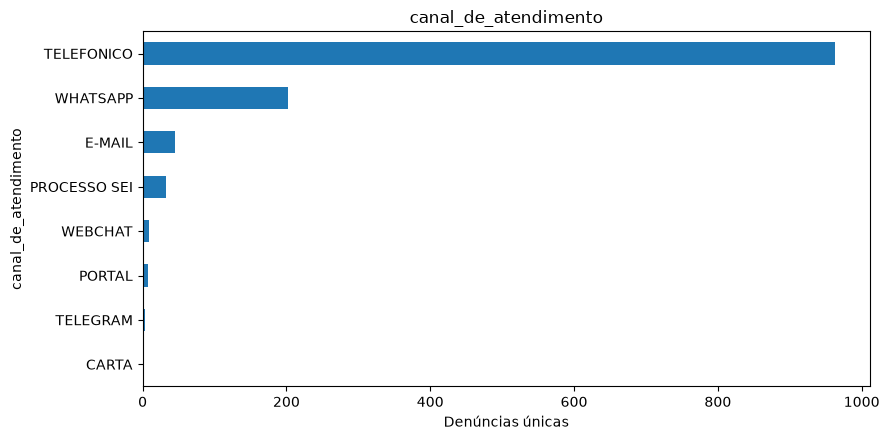

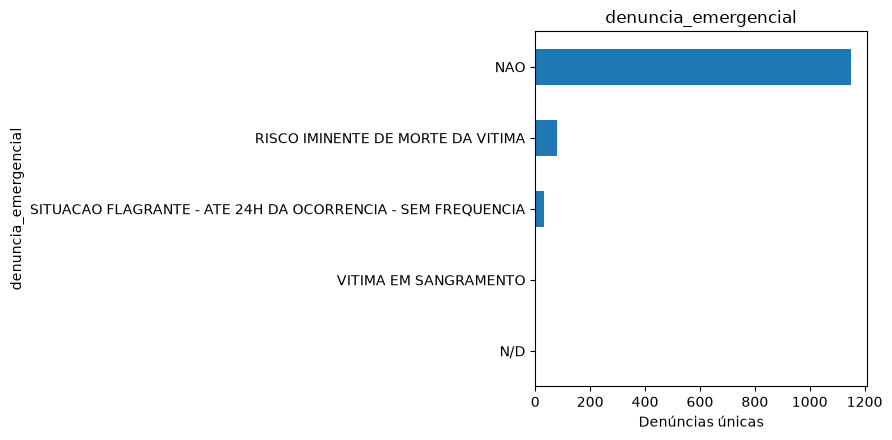

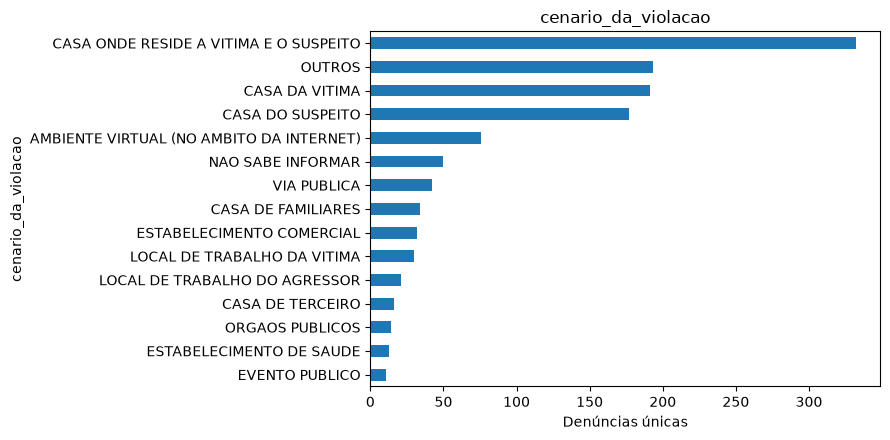

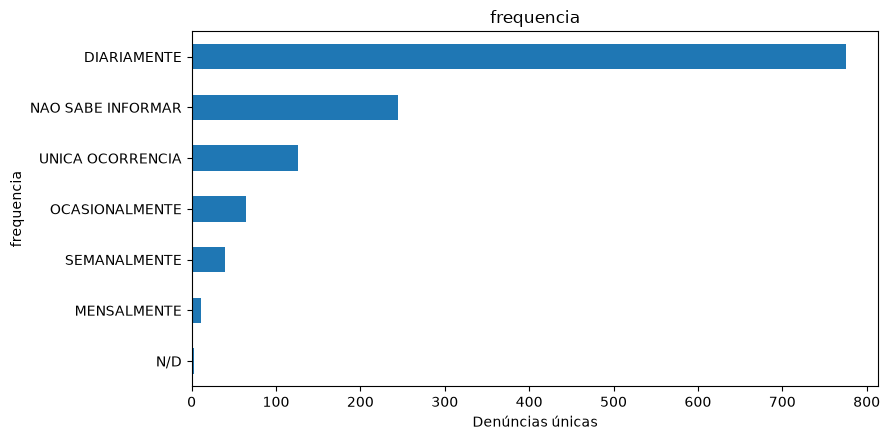

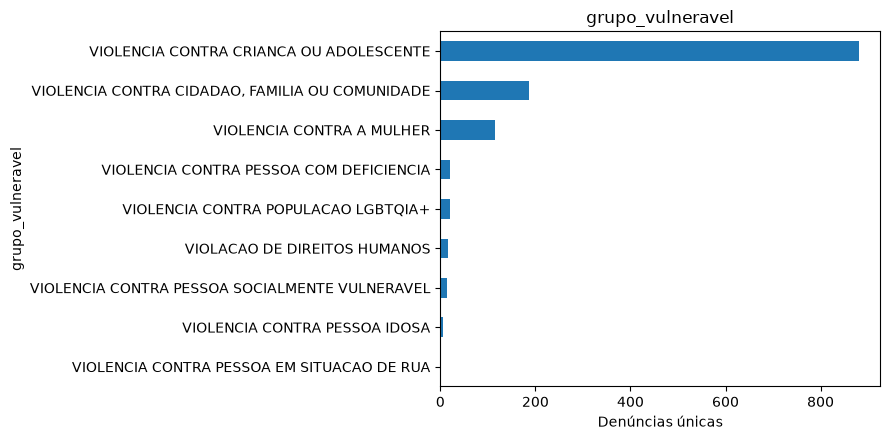

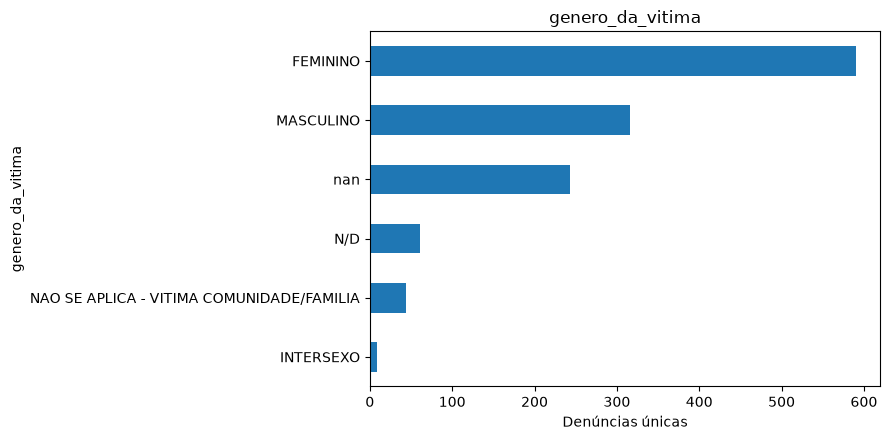

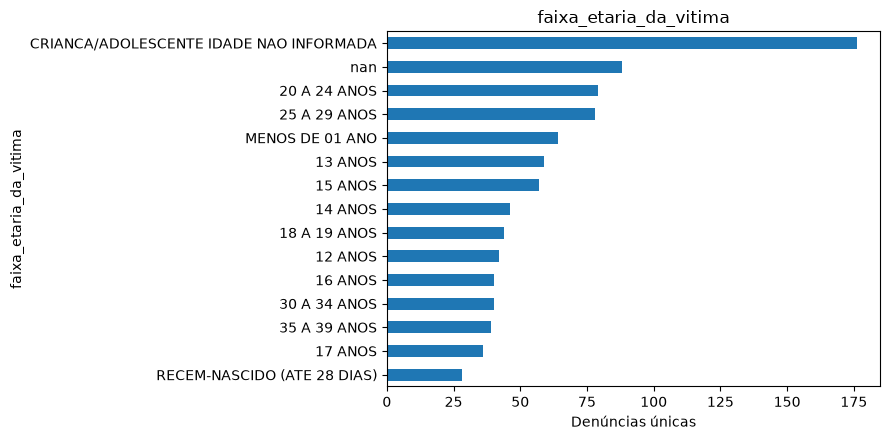

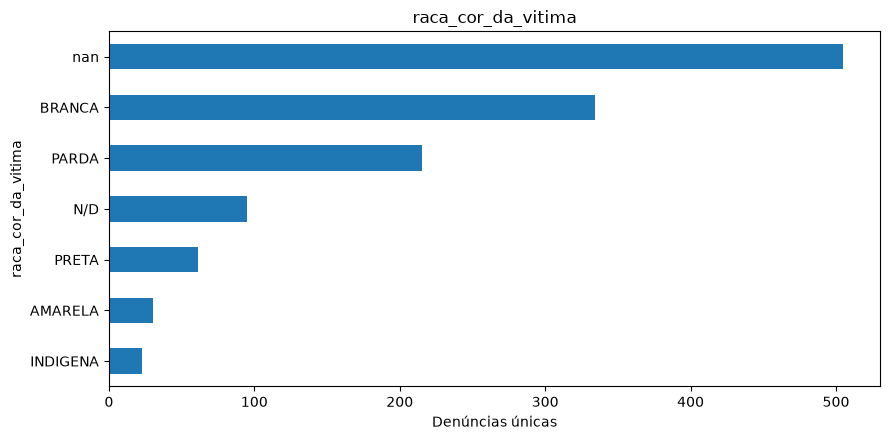

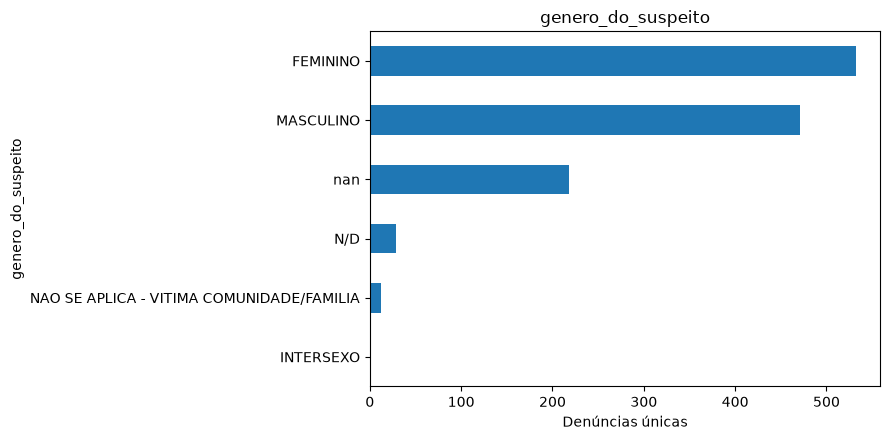

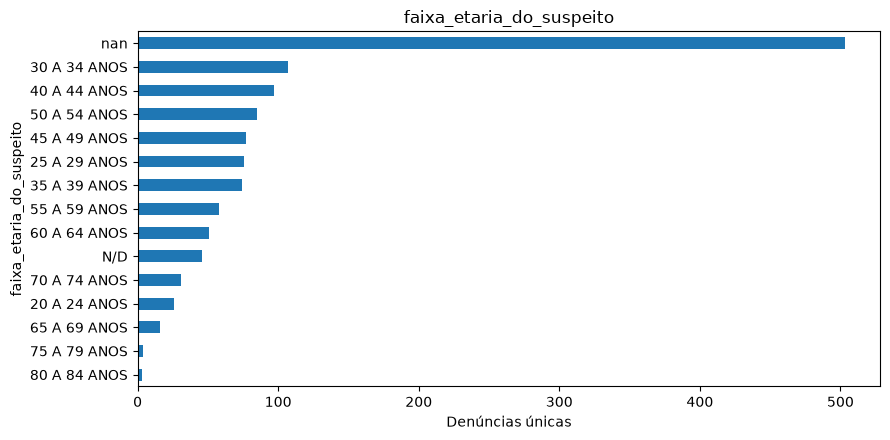

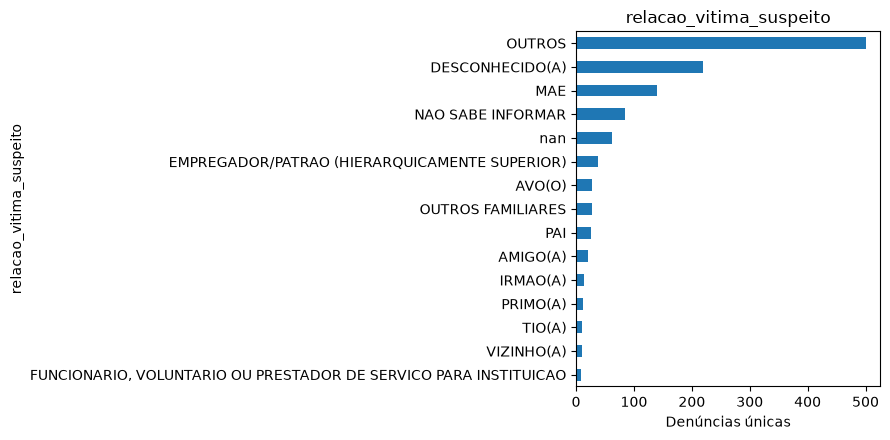

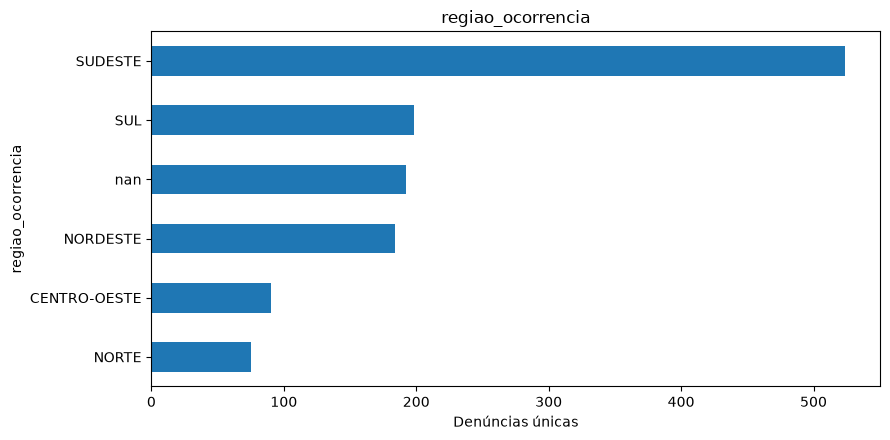

In [22]:
# Evita contagem duplicada quando um hash possui várias violações.
denuncias=df.sort_values("data_de_cadastro").drop_duplicates("hash",keep="first").copy()
print("Denúncias únicas:",len(denuncias))

def grafico_frequencia(col,n=15):
    s=denuncias[col].value_counts(dropna=False).head(n).sort_values()
    s.plot(kind="barh",figsize=(9,max(4,n*.3)),title=col)
    plt.xlabel("Denúncias únicas"); plt.tight_layout(); plt.show()

for col in ["canal_de_atendimento","denuncia_emergencial","cenario_da_violacao","frequencia","grupo_vulneravel","genero_da_vitima","faixa_etaria_da_vitima","raca_cor_da_vitima","genero_do_suspeito","faixa_etaria_do_suspeito","relacao_vitima_suspeito","regiao_ocorrencia"]:
    if col in denuncias.columns: grafico_frequencia(col)


### 6.1 Série temporal


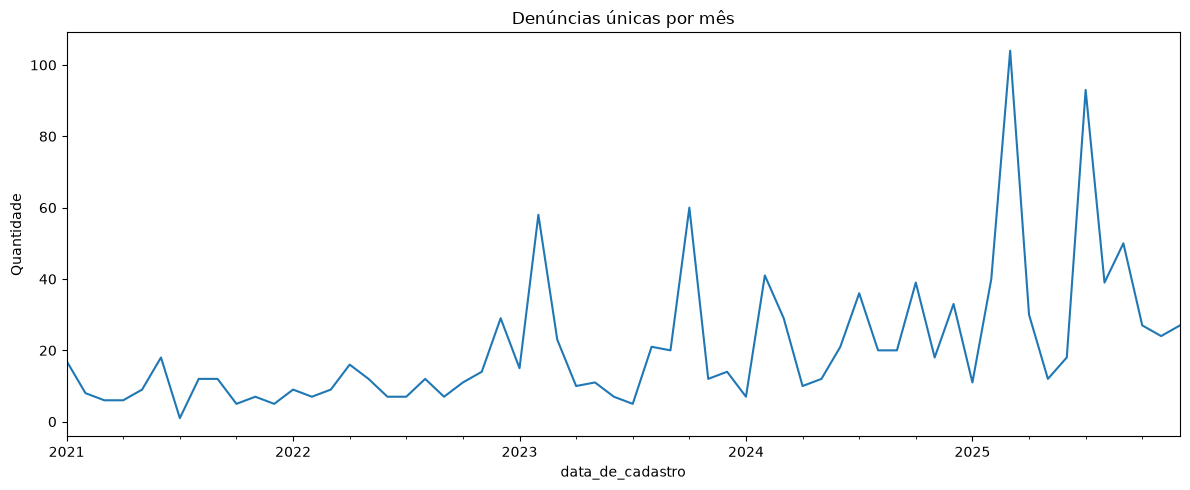

In [23]:
serie=denuncias.set_index("data_de_cadastro").resample("MS").size()
serie.plot(figsize=(12,5),title="Denúncias únicas por mês")
plt.ylabel("Quantidade"); plt.tight_layout(); plt.show()


### 6.2 Violações e coocorrências


In [24]:
# Funciona tanto com uma violação por linha quanto com valores separados por ; ou |.
viol_long=(df[["hash","violacao"]].dropna().assign(violacao=lambda x:x["violacao"].str.split(r"\s*[;|]\s*",regex=True)).explode("violacao"))
viol_long["violacao"]=viol_long["violacao"].str.strip()
viol_long=viol_long[viol_long["violacao"].ne("")].drop_duplicates()
matriz_violacoes=pd.crosstab(viol_long["hash"],viol_long["violacao"]).clip(upper=1).astype("int8")

freq=matriz_violacoes.sum().sort_values(ascending=False)
display(freq.head(30).to_frame("denuncias"))
cooc=matriz_violacoes.T.dot(matriz_violacoes)
cooc=cooc.mask(np.eye(len(cooc),dtype=bool),0)
display(cooc.stack().sort_values(ascending=False).head(30).to_frame("coocorrencias"))


,denuncias
violacao,
INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA,499
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIANCAS - NACIONAL,496
INTEGRIDADE>NEGLIGENCIA,464
INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE,462
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - NACIONAL,359
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - INTERNACIONAL,335
LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL,332
INTEGRIDADE>PSIQUICA>AMEACA OU COACAO,314
INTEGRIDADE>PSIQUICA>CONSTRANGIMENTO,310


coocorrencias
violacao                                           violacao                                                         
LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO           INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA                         126
INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA              LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO                      126
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO... INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE                 125
INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE      LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO...            125
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO... INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA                         124
INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA              LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO...            124
                                                   INTEGRIDADE>FISICA>OUTROS                                     118
INTEGRIDADE>FISICA>OUTROS                          INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA                         118
INTEGRIDADE>FISICA>MAUS TRATOS                     INTEGRIDADE>PSIQUICA>CONSTRANGIMENTO                          117
INTEGRIDADE>PSIQUICA>CONSTRANGIMENTO               INTEGRIDADE>FISICA>MAUS TRATOS                                117
INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE      LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO                      115
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIAN... LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL                     115
LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO           INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE                 115
LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL          LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIAN...            115
INTEGRIDADE>FISICA>MAUS TRATOS                     INTEGRIDADE>PSIQUICA>AMEACA OU COACAO                         111
INTEGRIDADE>PSIQUICA>AMEACA OU COACAO              INTEGRIDADE>FISICA>MAUS TRATOS                                111
INTEGRIDADE>FISICA>MAUS TRATOS                     LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIAN...            110
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIAN... INTEGRIDADE>FISICA>MAUS TRATOS                                110
INTEGRIDADE>PSIQUICA>AMEACA OU COACAO              LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL                     108
LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL          INTEGRIDADE>PSIQUICA>AMEACA OU COACAO                         108
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO... INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE                 104
INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE      LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO...            104
INTEGRIDADE>PSIQUICA>AMEACA OU COACAO              INTEGRIDADE>PSIQUICA>EXPOSICAO                                103
INTEGRIDADE>PSIQUICA>EXPOSICAO                     INTEGRIDADE>PSIQUICA>AMEACA OU COACAO                         103
INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA              LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO...            102
LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO           INTEGRIDADE>NEGLIGENCIA                                       102
LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSO... INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA                         102
INTEGRIDADE>NEGLIGENCIA                            LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO                      102
INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA              INTEGRIDADE>FISICA>AGRESSAO OU VIAS DE FATO                   101
INTEGRIDADE>FISICA>AGRESSAO OU VIAS DE FATO        INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA                         101

## 7. Agregação por hash para modelagem


In [25]:
def moda_segura(s):
    m=s.dropna().mode()
    return m.iloc[0] if not m.empty else np.nan

# Colunas descritivas: moda. Quantidade: máximo. Data: mínimo.
model_base=df.groupby("hash",as_index=True).agg({
    "data_de_cadastro":"min",
    "sl_quantidade_vitimas":"max",
    **{c:moda_segura for c in df.columns if c not in {"hash","data_de_cadastro","sl_quantidade_vitimas","violacao"}}
})
viol_long=(df[["hash","violacao"]].dropna().assign(violacao=lambda x:x["violacao"].str.split(r"\s*[;|]\s*",regex=True)).explode("violacao"))
viol_long["violacao"]=viol_long["violacao"].str.strip()
viol_long=viol_long[viol_long["violacao"].ne("")].drop_duplicates()
matriz_violacoes=pd.crosstab(viol_long["hash"],viol_long["violacao"]).clip(upper=1).astype("int8")
model_base=model_base.join(matriz_violacoes.add_prefix("violacao__"),how="left")
viol_cols=[c for c in model_base.columns if c.startswith("violacao__")]
model_base[viol_cols]=model_base[viol_cols].fillna(0).astype("int8")
model_base["qtd_tipos_violacao"]=model_base[viol_cols].sum(axis=1)
model_base["multiplas_violacoes"]=(model_base["qtd_tipos_violacao"]>1).astype("int8")
model_base.shape


(1263, 149)

In [26]:
model_base

,data_de_cadastro,sl_quantidade_vitimas,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,deficiencia_da_vitima,doenca_rara_da_vitima,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,raca_cor_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,deficiencia_do_suspeito,doenca_rara_do_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,raca_cor_do_suspeito,sl_suspeito_ramo,ano_cadastro,mes_cadastro,trimestre_cadastro,dia_semana_cadastro,regiao_ocorrencia,regiao_vitima,regiao_suspeito,violacao__DIREITOS CIVIS E POLITICOS>ACESSO A INFORMACAO,violacao__DIREITOS CIVIS E POLITICOS>CULTURAL,violacao__DIREITOS CIVIS E POLITICOS>LIVRE EXERCICIO DO PODER FAMILIAR,violacao__DIREITOS CIVIS E POLITICOS>MEMORIA E VERDADE,violacao__DIREITOS CIVIS E POLITICOS>NACIONALIDADE,violacao__DIREITOS CIVIS E POLITICOS>PROPRIEDADE>PATRIMONIO GENETICO,violacao__DIREITOS CIVIS E POLITICOS>PROPRIEDADE>PATRIMONIO IMATERIAL,violacao__DIREITOS CIVIS E POLITICOS>PROPRIEDADE>PATRIMONIO MATERIAL,violacao__DIREITOS CIVIS E POLITICOS>RETENCAO DE DOCUMENTOS,violacao__DIREITOS SOCIAIS>ALIMENTACAO,violacao__DIREITOS SOCIAIS>ASSISTENCIA AOS DESAMPARADOS,violacao__DIREITOS SOCIAIS>EDUCACAO,violacao__DIREITOS SOCIAIS>LAZER,violacao__DIREITOS SOCIAIS>MORADIA,violacao__DIREITOS SOCIAIS>PROTECAO A INFANCIA,violacao__DIREITOS SOCIAIS>PROTECAO A MATERNIDADE,violacao__DIREITOS SOCIAIS>SAUDE,violacao__DIREITOS SOCIAIS>SEGURANCA,violacao__DIREITOS SOCIAIS>TRABALHO>NEGLIGENCIA INTITUCIONAL>CONDICOES DE TRABALHO INDIGNAS OU DEGRADANTES,violacao__DIREITOS SOCIAIS>TRABALHO>NEGLIGENCIA INTITUCIONAL>OMISSAO DE ATENDIMENTO A SOFRIMENTO PSIQUICO,violacao__DIREITOS SOCIAIS>TRABALHO>PRATICAS INSTITUCIONAIS QUE VIOLAM DIREITOS HUMANOS>INCITACAO OU CONSTRANGIMENTO A COMPORTAMENTOS NAO COERENTES COM OS DIREITOS HUMANOS,violacao__DIREITOS SOCIAIS>TRABALHO>PRATICAS INSTITUCIONAIS QUE VIOLAM DIREITOS HUMANOS>PROCEDIMENTOS EXPLICITOS EM PROTOCOLOS OU MANUAIS NAO COERENTES COM OS DIREITOS HUMANOS,violacao__IGUALDADE>DISCRIMINACAO,violacao__IGUALDADE>INJURIA RACIAL E ETNICA,violacao__IGUALDADE>RACISMO,violacao__INTEGRIDADE>FISICA>ABANDONO,violacao__INTEGRIDADE>FISICA>AGRESSAO OU VIAS DE FATO,violacao__INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE,violacao__INTEGRIDADE>FISICA>INSUBSISTENCIA INTELECTUAL,violacao__INTEGRIDADE>FISICA>INSUBSISTENCIA MATERIAL,violacao__INTEGRIDADE>FISICA>LESAO CORPORAL,violacao__INTEGRIDADE>FISICA>MAUS TRATOS,violacao__INTEGRIDADE>FISICA>OUTROS,violacao__INTEGRIDADE>FISICA>SITUACAO DE RUA OU ABANDONO MATERIAL,violacao__INTEGRIDADE>FISICA>TORTURA FISICA,violacao__INTEGRIDADE>FISICA>VIOLENCIA OBSTETRICA,violacao__INTEGRIDADE>NEGLIGENCIA,violacao__INTEGRIDADE>PATRIMONIAL>COLETIVO,violacao__INTEGRIDADE>PATRIMONIAL>INDIVIDUAL,violacao__INTEGRIDADE>PSIQUICA>ALIENACAO PARENTAL,violacao__INTEGRIDADE>PSIQUICA>AMEACA OU COACAO,violacao__INTEGRIDADE>PSIQUICA>ASSEDIO MORAL,violacao__INTEGRIDADE>PSIQUICA>CALUNIA,violacao__INTEGRIDADE>PSIQUICA>CONSTRANGIMENTO,violacao__INTEGRIDADE>PSIQUICA>DIFAMACAO,violacao__INTEGRIDADE>PSIQUICA>EXPOSICAO,violacao__INTEGRIDADE>PSIQUICA>EXPOSICAO (EROTIZACAO),violacao__INTEGRIDADE>PSIQUICA>INJURIA,violacao__INTEGRIDADE>PSIQUICA>INSUBSISTENCIA AFETIVA,violacao__INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA,violacao__LIBERDADE>DE RELIGIAO OU CRENCA>DE CULTO,violacao__LIBERDADE>DE RELIGIAO OU CRENCA>NAO CRENCA,violacao__LIBERDADE>DIREITOS INDIVIDUAIS>AUTONOMIA DE VONTADE,violacao__LIBERDADE>DIREITOS INDIVIDUAIS>CARCERE PRIVADO,violacao__LIBERDADE>DIREITOS INDIVIDUAIS>CONDICAO ANALOGA A DE ESCRAVO>RESTRIGIR A LOCOMOCAO DE TRABALHADOR EM RAZAO DE DIVIDA,violacao__LIBERDADE>DIREITOS INDIV

## 8. Exportação


In [27]:
df.to_parquet(OUTPUT_DIR/"disque100_linhas_tratadas.parquet",index=False)
model_base.reset_index().to_parquet(OUTPUT_DIR/"disque100_denuncias_modelagem.parquet",index=False)
matriz_violacoes.reset_index().to_parquet(OUTPUT_DIR/"matriz_violacoes_por_denuncia.parquet",index=False)
relatorio_correcoes.to_csv(OUTPUT_DIR/"relatorio_correcoes.csv",index=False,encoding="utf-8-sig")
comparacao.to_csv(OUTPUT_DIR/"comparacao_antes_depois.csv",encoding="utf-8-sig")
relatorio_missing_explicito.to_csv(OUTPUT_DIR/"relatorio_missing_explicito.csv",encoding="utf-8-sig")
print("Arquivos exportados para",OUTPUT_DIR.resolve())


Arquivos exportados para C:\Projetos\eda-disque100-completo\outros_notebooks_para_analisar\results


## 9. Registro de decisões e achados

Documente versões, filtros, categorias consolidadas, colunas removidas e justificativas.
